In [107]:
import sys
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler
import sklearn
import numpy as np
import pandas as pd
import yaml
import statsmodels.api as sm


sys.path.insert(0, str(Path.cwd().parent))

from utils.geo import add_landmark_distances
from utils.map_graph import create_map, show_map
from utils.triple_plot import normality_report
from utils.pca_plots import plot_scree, plot_loadings
from utils.fast_OLS import DiagnosticoOLS
from utils.vif_resume import vif_table

sklearn.set_config(transform_output="pandas")

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"
GEO_DIR = ROOT_DIR / "geodata"

In [3]:
df = pd.read_csv(DATA_DIR / 'datos_inmobiliarios_ready.csv')

In [4]:
bogota_marks_yaml_path = GEO_DIR / "bogota_landmarks.yaml"
with open(bogota_marks_yaml_path, "r", encoding="utf-8") as file:
    geo_data = yaml.safe_load(file)

# Generar variables de distancia a `landmarks` positvos y negativos

Un landmark positivo es un factor que se cree sera de plusvalia para el inmueble, mientras que uno negativo se espera suponga una reduccion en el precio de este, las siguientes variables se basan en mostrar la distancia de cada vivienda a su landmark de cada tipo mas cercano

In [5]:
positive_landmarks = geo_data.get("positive_landmarks", {})
negative_landmarks = geo_data.get("negative_landmarks", {})

df_pos = pd.DataFrame.from_dict(positive_landmarks, orient="index").assign(
    label="positive"
)
df_neg = pd.DataFrame.from_dict(negative_landmarks, orient="index").assign(
    label="negative"
)
df_landmarks = pd.concat([df_pos, df_neg])
df_landmarks = df_landmarks.reset_index().rename(
    columns={"index": "landmark_name"}
)

In [6]:
show_map(
    create_map(
        df_landmarks,
        name_col="landmark_name",
        label_col="label",
        colors={"positive": "green", "negative": "red"},
        cluster=False,
    )
)

In [7]:
df = add_landmark_distances(df_houses=df, df_landmarks=df_landmarks)

# Seleccionar variables continuas a usar

Se van a utilizar variables que son en si continuas, y por falta de variables puramente continuas se va a tomar las variables numericas discretas con varios valores posibles como continuas, esto se ve sustentado en que ya que con rangos amplios las varibales discretas presentan un comportamiento similar a una continua.

In [88]:
numeric_purpoused_cols = ['price_amount',
                            'admin_fee',
                            'latitude',
                            'longitude',
                            'locality_frec',
                            'n_amenities',
                            'neighborhood_grouped_frec',
                            'dist_nearest_positive_km',
                            'dist_nearest_negative_km',
                        ]

numeric_pca_cols = []

for col in numeric_purpoused_cols:
    n_unique = df[col].nunique()
    if n_unique >= 10:
        print(f'La columna {col} tiene {n_unique} valores unicos, se puede usar en PCA')
        numeric_pca_cols.append(col)
    else:
        print(f'La columna {col} tiene {n_unique} valores unicos, NO SE USA')
    print('-'*85,'\n')

La columna price_amount tiene 1638 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna admin_fee tiene 9244 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna latitude tiene 16126 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna longitude tiene 15913 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna locality_frec tiene 19 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna n_amenities tiene 65 valores unicos, se puede usar en PCA
------------------------------------------------------------------------------------- 

La columna neighborhood_grouped_frec tiene 20 valore

In [9]:
len(numeric_pca_cols)

9

# Analizar escalas

findfont: Failed to find font weight medium, now using 400.


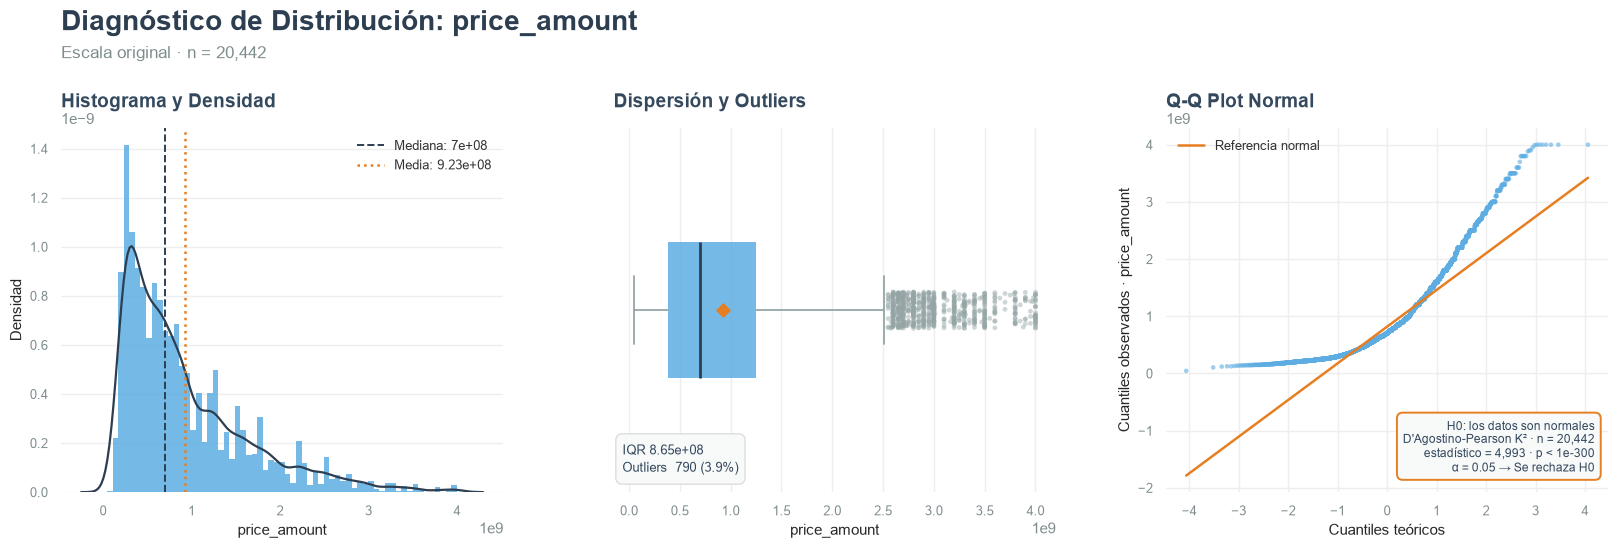

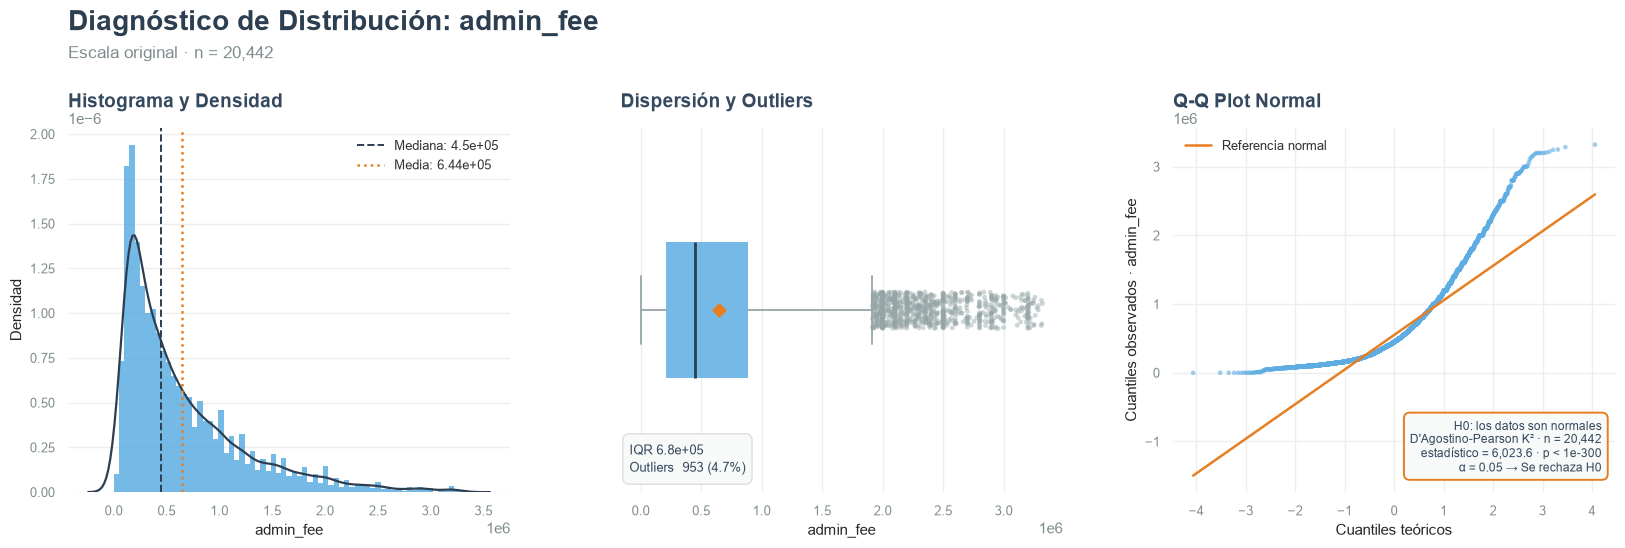

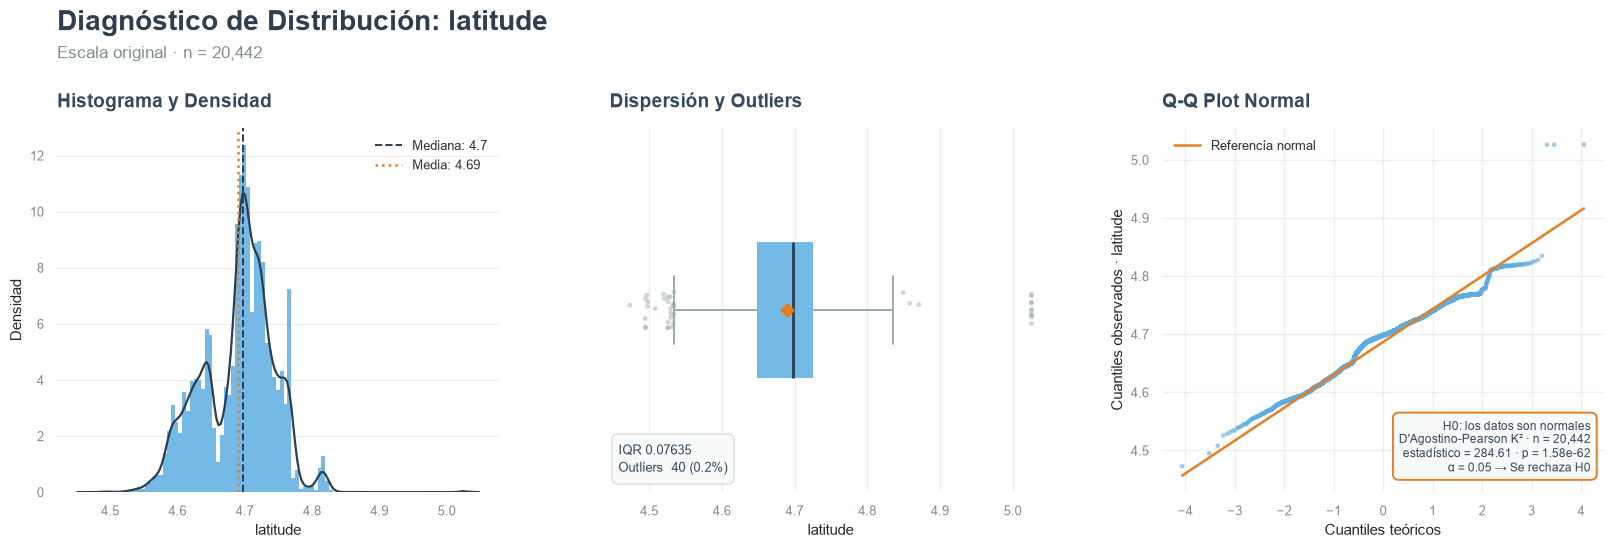

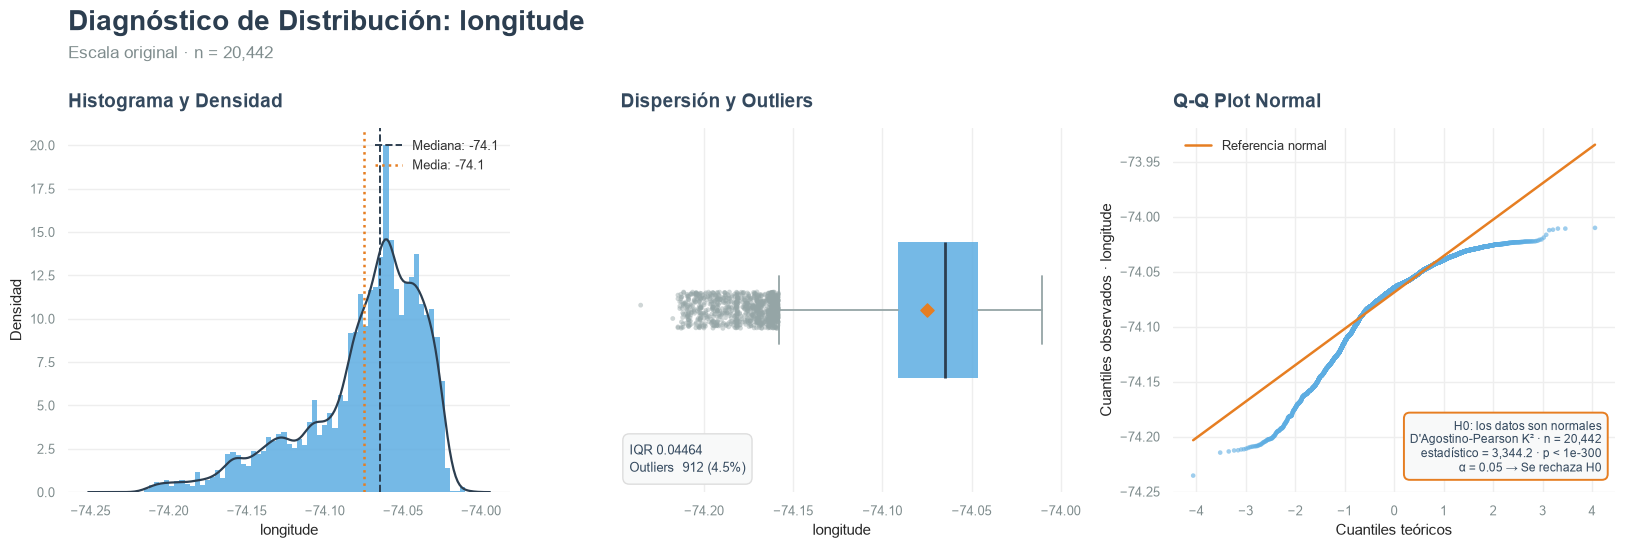

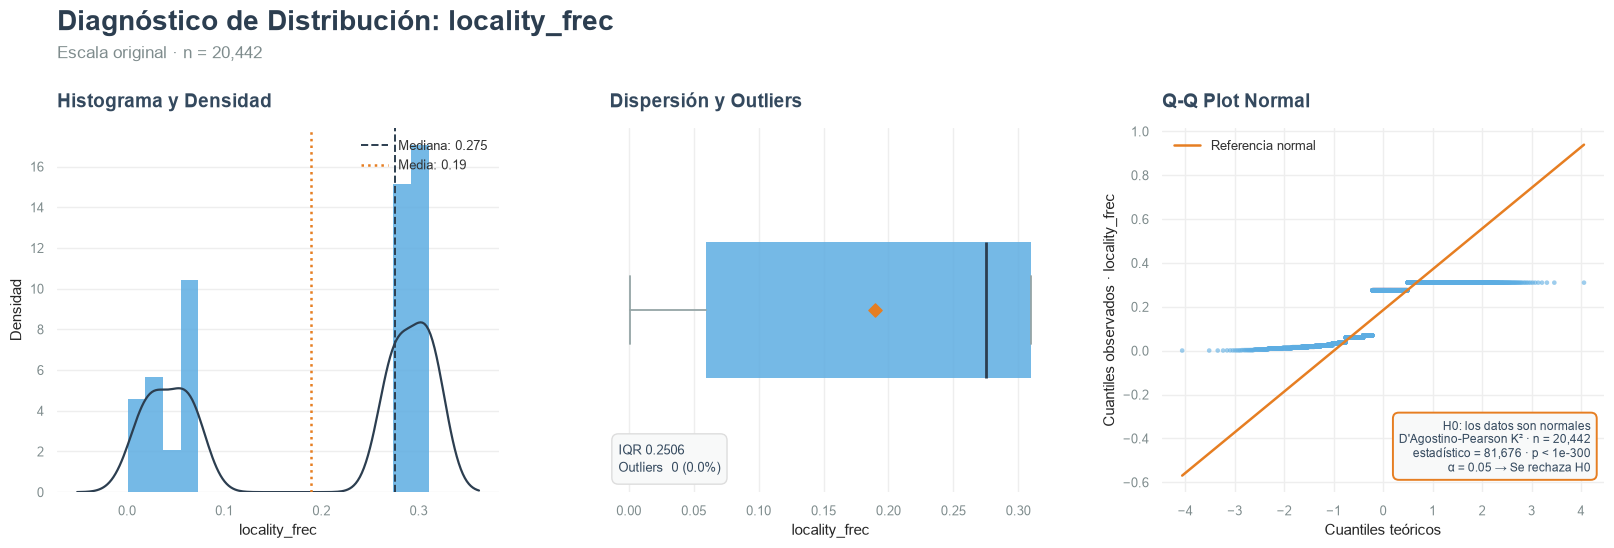

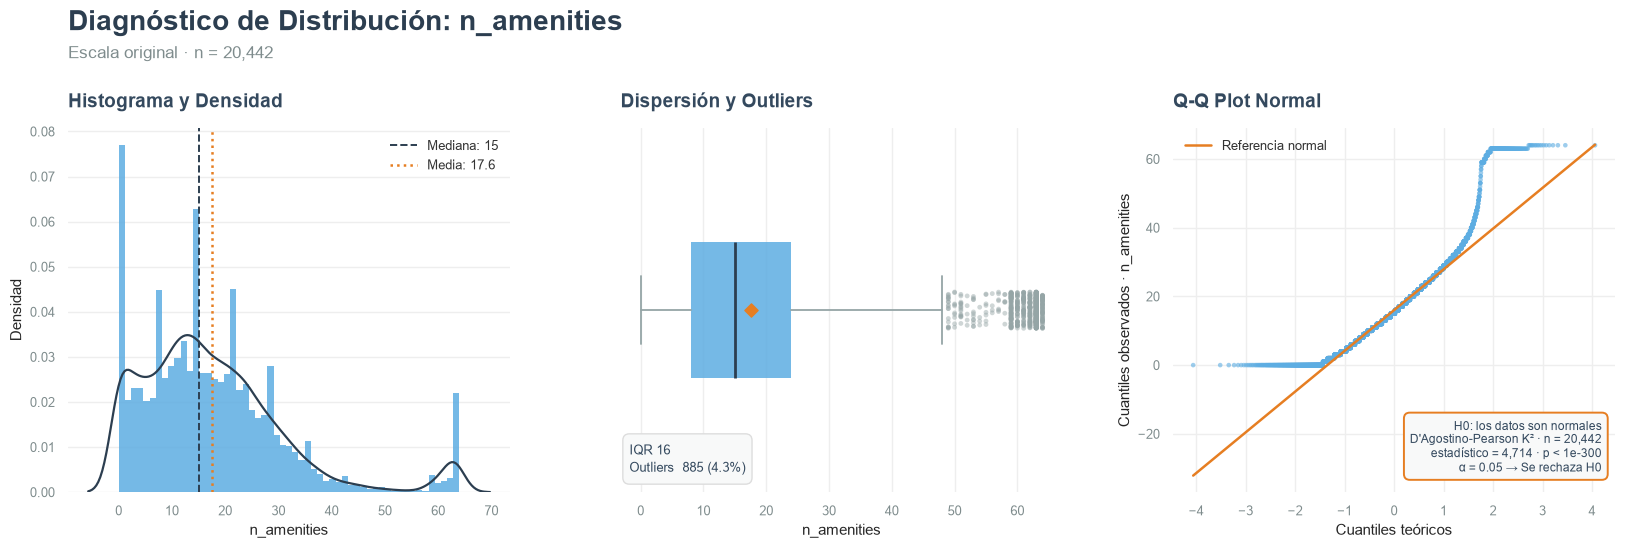

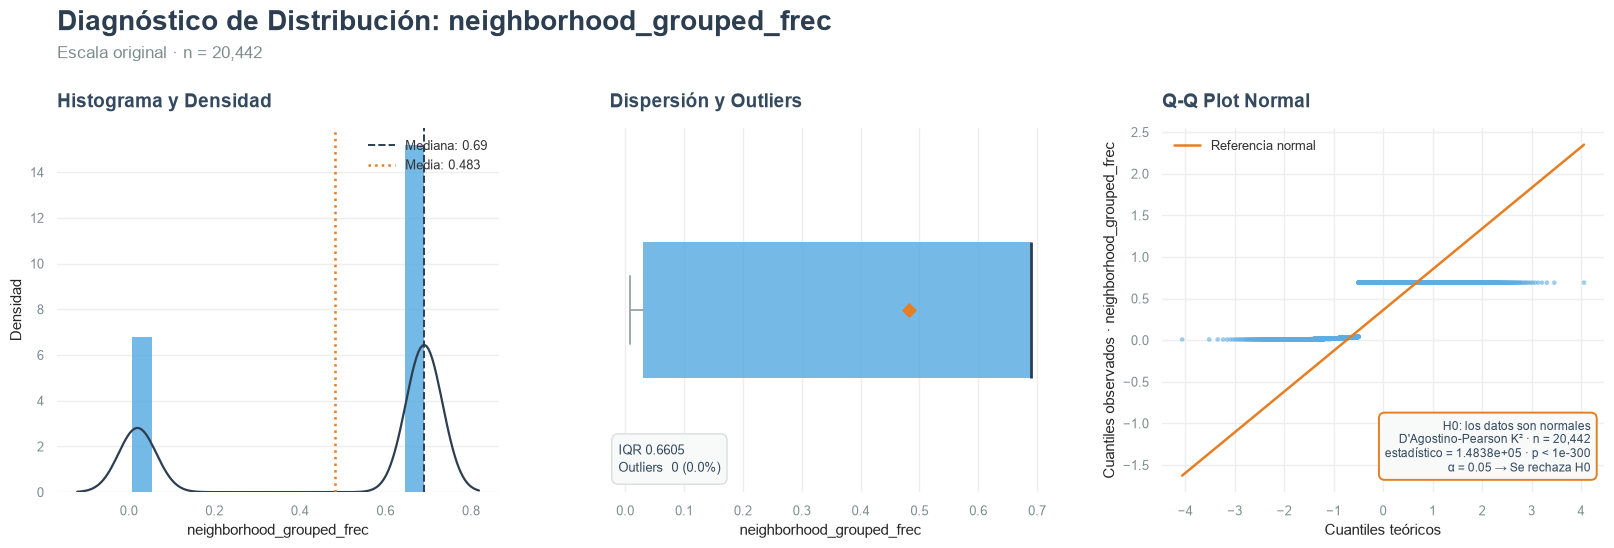

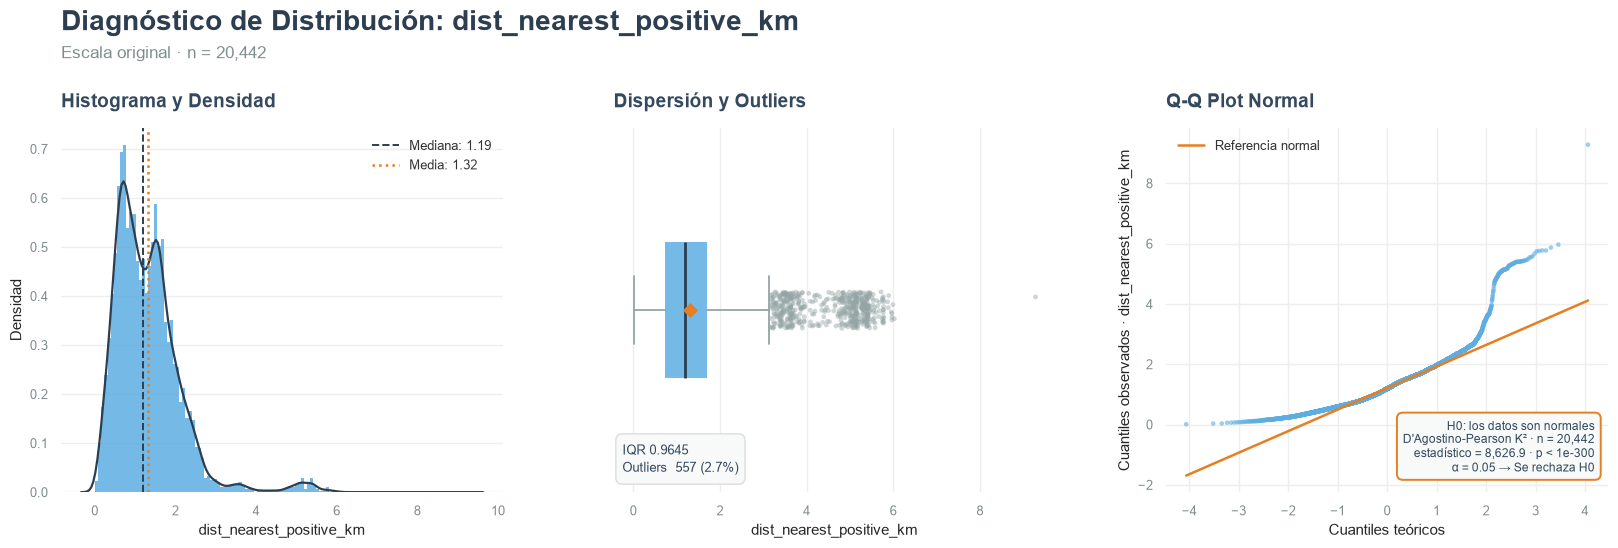

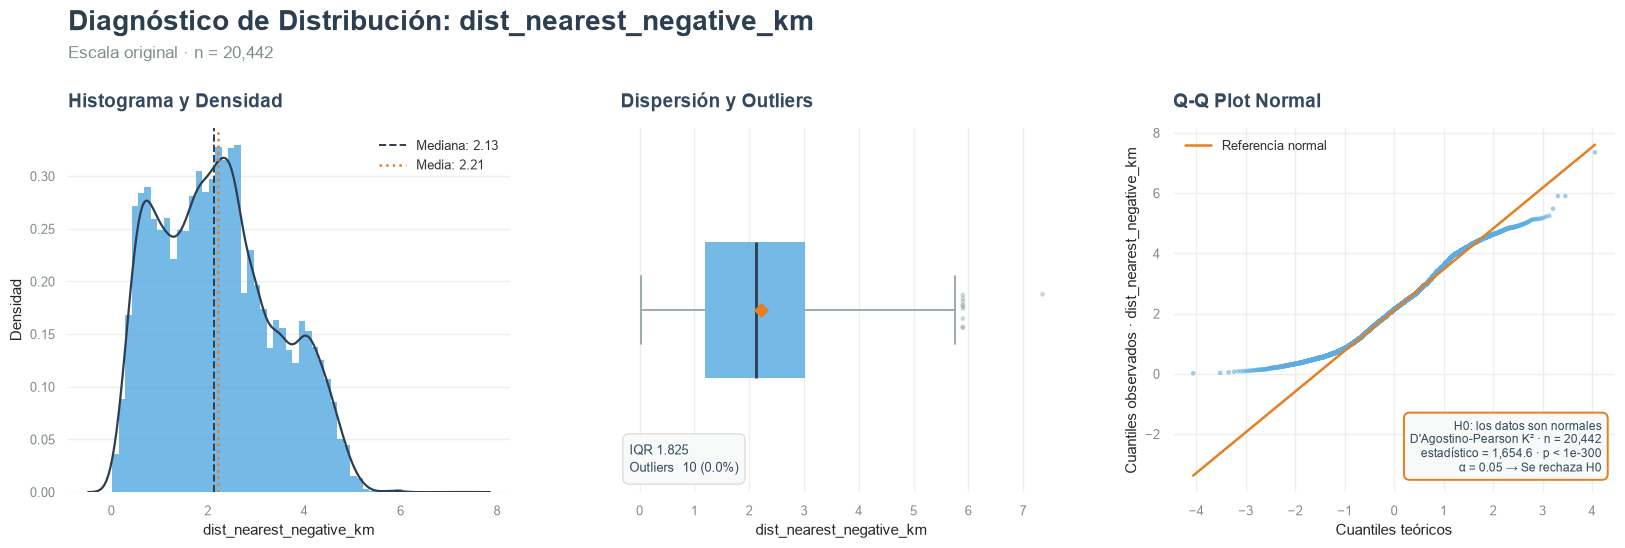

In [10]:
for col in numeric_pca_cols:
    normality_report(df, col)

Note que multiples variables tienen sesgo a la derecha, luego la media podria no representar el centro de los datos y no hacer efecvtivo el paso de centrar los datos en el oriogen geometrico, por lo tanto se van a provar 2 enfoques. El primero consta de estandarizar las variables tal como estan, ver como se comportan sus componentes y que tanto es el error de reconstruccion, y el segundo consta en primero aplicar transofrmaciones como logaritmos esto con el fin de aproximar las variables a una campana y despues estandarizar.

> Note que siempre se plantea la estandarizacion, esto se hace ya que las variables estan en escalas muy dispares, por ejemplo se tienen proporciones y precios en COP.

# Aplicar PCA 

A continuacion se mostraran 2 formas de enfocar PCA, uno descriptivo donde se usaran todas las variables, para identificar las direcciones de mayor variabilidad e interpretar los loadings de las direcciones, y un enfoque dirigido al pre procesamiento de datos, donde se excluira la variable `price_amount`, despues se seleccionaran componentes tales que expliquen por lo menos el 80% de la variabilidad en menos dimensionalidad, para posteriormente interpretar los loadings y ajustar una regresion lineal con este nuevo conjunto, se comparara el rendimiento de esta regresion con la ejecutada en el cuaderno `notebooks/model_OLS.ipynb`.

## Usando todo el set

### Usando las variables originales (estandarizadas)


In [11]:
df_pca = df[numeric_pca_cols].copy()

In [12]:
df_pca_std = StandardScaler().fit_transform(df_pca)

In [13]:
df_pca_std.describe() # los datos estan centrados y en media 0, aunque el
                      # numero no es exactamente 0 es valido pues es una de las propiedades de
                      # StandardScaler

,price_amount,admin_fee,latitude,longitude,locality_frec,n_amenities,neighborhood_grouped_frec,dist_nearest_positive_km,dist_nearest_negative_km
count,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04,2.044200e+04
mean,1.112287e-16,-1.334744e-16,1.084480e-16,-1.575221e-13,2.502645e-17,-1.279130e-16,1.724045e-16,-1.112287e-16,-2.085538e-16
std,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00
min,-1.240646e+00,-1.107874e+00,-4.082441e+00,-4.170268e+00,-1.504465e+00,-1.271803e+00,-1.534401e+00,-1.571186e+00,-1.810379e+00
25%,-7.605389e-01,-7.464108e-01,-7.849832e-01,-4.270008e-01,-1.035203e+00,-6.921312e-01,-1.462249e+00,-7.081365e-01,-8.318795e-01
50%,-3.149048e-01,-3.333085e-01,1.501185e-01,2.612787e-01,6.847750e-01,-1.849188e-01,6.694747e-01,-1.531854e-01,-6.114816e-02
75%,4.631866e-01,4.240457e-01,6.511599e-01,7.315962e-01,9.614993e-01,4.672115e-01,6.694747e-01,4.522404e-01,6.788945e-01
max,4.353643e+00,4.608201e+00,6.316570e+00,1.676758e+00,9.614993e-01,3.365568e+00,6.694747e-01,9.585711e+00,4.260418e+00


In [14]:
pca_org = PCA()

In [15]:
df_pca = pca_org.fit_transform(df_pca_std)

In [16]:
pca_org.explained_variance_ratio_ * 100

array([39.07970869, 14.85138268, 12.01414905,  9.91004486,  8.67533068,
        7.33250576,  3.79382854,  2.87178881,  1.47126093])

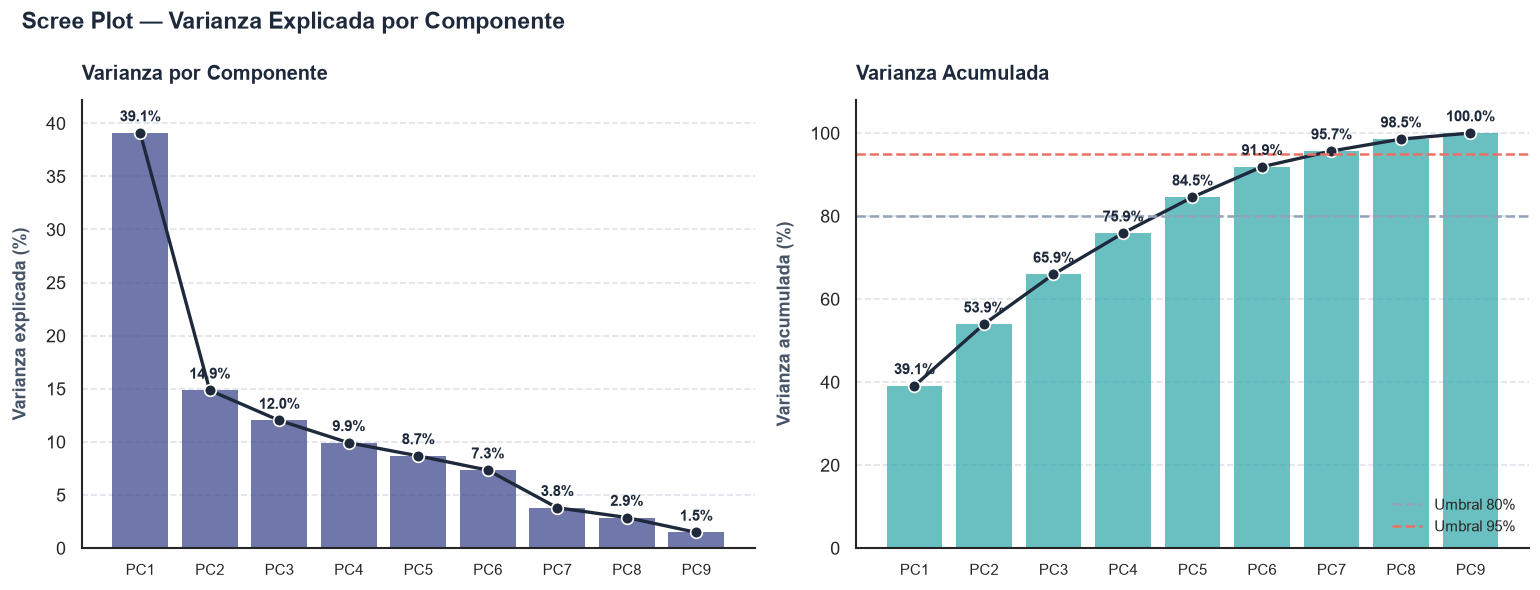

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 3 componente(s)



(<Figure size 1560x600 with 2 Axes>,
 array([<Axes: title={'left': 'Varianza por Componente'}, ylabel='Varianza explicada (%)'>,
        <Axes: title={'left': 'Varianza Acumulada'}, ylabel='Varianza acumulada (%)'>],
       dtype=object))

In [17]:
plot_scree(pca_org)

Vea que con 5 componentes se obtiene una varianza explicada del 84.5%, ahora se da paso a interpretar sus cargas

In [32]:
pca_org_5 = PCA(n_components=5)
df_pca_5 = pca_org_5.fit_transform(df_pca_std)

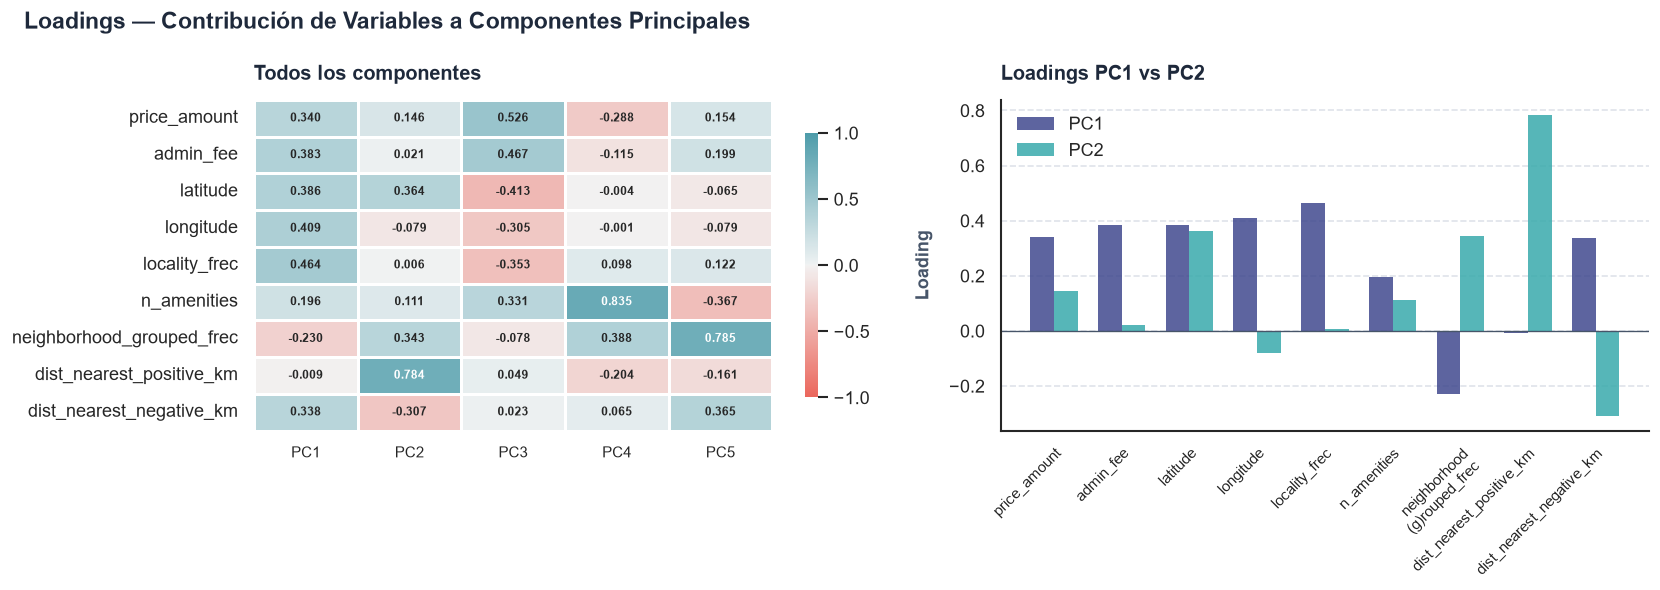

In [33]:
out = plot_loadings(pca_org_5, numeric_pca_cols)

La primera componente combina características económicas y geográficas de los inmuebles, describiendo viviendas con precios y cuotas de administración elevados relacionados con su ubicación. Mientras que PC2 representa a viviendas alejadas de landmarks positivos y cercanas a puntos negativos.

Por otro lado, la tercera componente describe viviendas costosas, con administración elevada y PC4 viviendas con muchas amenidades, ubicadas en barrios más frecuentes en la muestra y con tendencia a presentar precios más bajos.

Por último, PC5 representa viviendas en barrios más frecuentes, con menos amenidades y alejadas de landmarks negativos.

In [39]:
df_rec_org = pca_org_5.inverse_transform(df_pca_5)

In [57]:
mse_error_org = np.mean((df_pca_std - df_rec_org) ** 2)

print(f"Error de reconstrucción promedio (MSE): {mse_error_org}")

Error de reconstrucción promedio (MSE): 0.15469384038637715


In [55]:
# Error cuadrático por variable (columnas)
mse_por_variable = np.mean((df_pca_std - df_rec_org) ** 2, axis=0)

# Si df_pca_std es un DataFrame, puedes presentarlo como Series
error_variables = pd.Series(mse_por_variable, index=df_pca_std.columns)
print("Error de reconstrucción por variable:")
display(error_variables.sort_values())

Error de reconstrucción por variable:


n_amenities                  0.002880
neighborhood_grouped_frec    0.033891
locality_frec                0.087695
latitude                     0.111673
dist_nearest_positive_km     0.117753
price_amount                 0.172371
admin_fee                    0.205688
longitude                    0.297408
dist_nearest_negative_km     0.362885
dtype: float64

### Usando las variables transformadas (estandarizadas)


In [49]:
df_features_pca = df[numeric_pca_cols].copy()
df_features_pca.min() <= 0

price_amount                 False
admin_fee                    False
latitude                     False
longitude                     True
locality_frec                False
n_amenities                   True
neighborhood_grouped_frec    False
dist_nearest_positive_km     False
dist_nearest_negative_km     False
dtype: bool

In [50]:
biased_cols = ['price_amount',
            'admin_fee',
            'latitude',
            'longitude',
            'n_amenities',
            'dist_nearest_positive_km',
            'dist_nearest_negative_km'
            ]

for col in biased_cols:
    if col == 'longitude':
        min_val = df_features_pca[col].min()
        shift = abs(min_val) + 1 if min_val < 0 else 0

        df_features_pca[f'{col}_log'] = np.log(df_features_pca[col] + shift)
    else:
        df_features_pca[f'{col}_log'] = np.log1p(df_features_pca[col])

    df_features_pca.drop(columns=[col], inplace=True)

In [52]:
len(df_features_pca.columns)

9

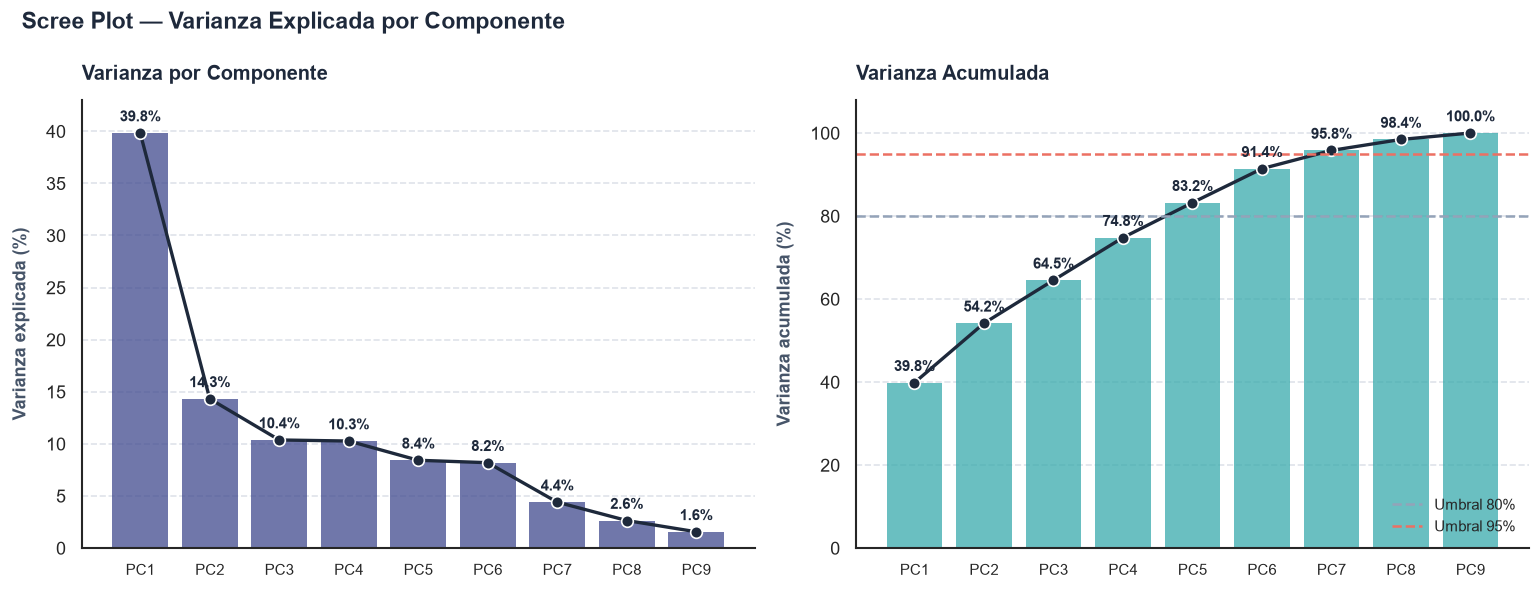

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 2 componente(s)



(<Figure size 1560x600 with 2 Axes>,
 array([<Axes: title={'left': 'Varianza por Componente'}, ylabel='Varianza explicada (%)'>,
        <Axes: title={'left': 'Varianza Acumulada'}, ylabel='Varianza acumulada (%)'>],
       dtype=object))

In [59]:
pca_org_trans = PCA()
df_features_pca_std = StandardScaler().fit_transform(df_features_pca)
df_pca_trans = pca_org_trans.fit_transform(df_features_pca_std)
plot_scree(pca_org_trans)

Note que con 5 componentes ahora esta explicando menos variabilidad, por lo que se podria pensar que en principio el modelo empeoro con esta trasnformacion. 

In [64]:
pca_org_trans_5 = PCA(n_components=5)
df_pca_5_trans = pca_org_trans_5.fit_transform(df_features_pca_std)

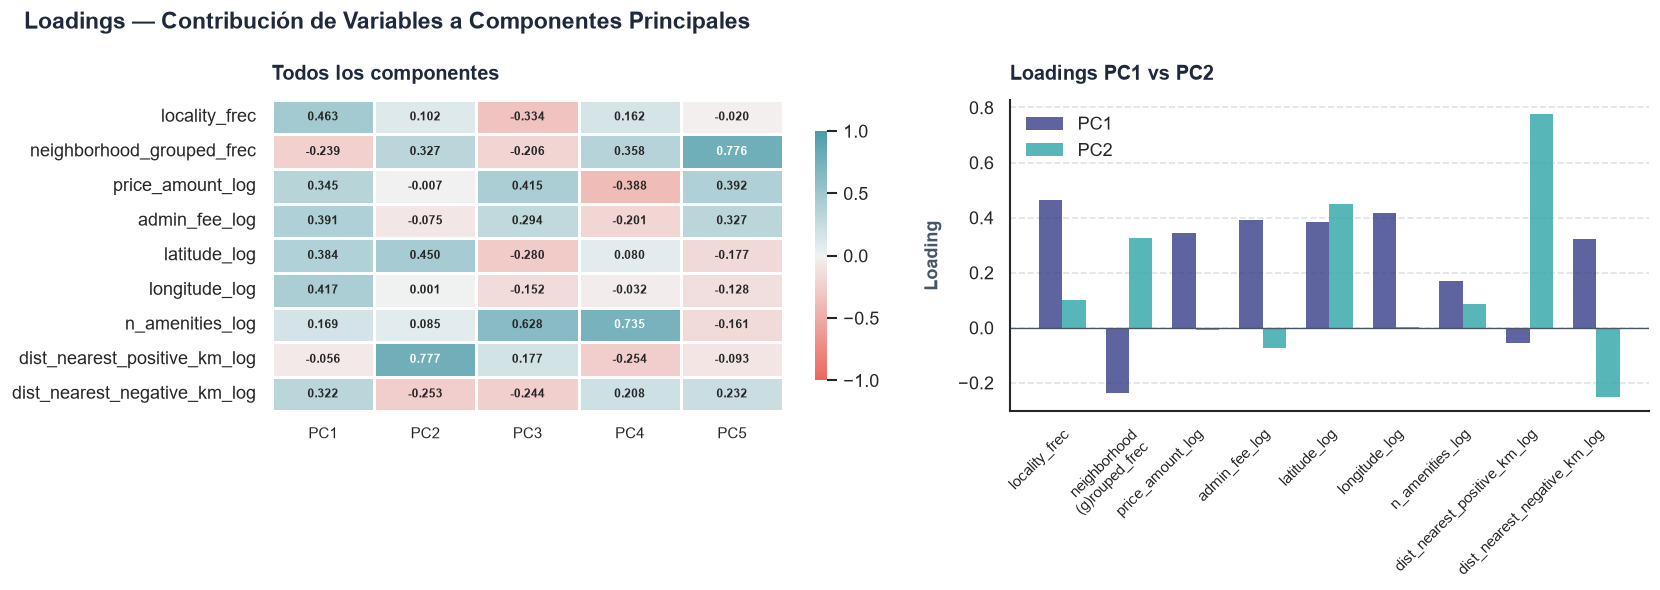

In [72]:
out = plot_loadings(pca_org_trans_5, df_features_pca_std.columns)

In [68]:
df_rec_org_trans = pca_org_trans_5.inverse_transform(df_pca_5_trans)

In [69]:
mse_error_org_trans = np.mean((df_features_pca_std - df_rec_org_trans) ** 2)

print(f"Error de reconstrucción promedio (MSE): {mse_error_org_trans}")

Error de reconstrucción promedio (MSE): 0.16786775921851088


In [73]:
# Error cuadrático por variable (columnas)
mse_por_variable = np.mean((df_features_pca_std - df_rec_org_trans) ** 2, axis=0)

# Si df_pca_std es un DataFrame, puedes presentarlo como Series
error_variables_trans = pd.Series(mse_por_variable, index=df_features_pca_std.columns)
print("Error de reconstrucción por variable:")
display(error_variables_trans.sort_values())

Error de reconstrucción por variable:


n_amenities_log                 0.001440
neighborhood_grouped_frec       0.043317
locality_frec                   0.090493
latitude_log                    0.106799
dist_nearest_positive_km_log    0.116236
price_amount_log                0.155969
admin_fee_log                   0.245690
longitude_log                   0.341825
dist_nearest_negative_km_log    0.409040
dtype: float64

### Conclusion 
A pesar de lo que se esperaba el PCA que no transformo las variables antes de ajustarse fue marginalmente mejor (0.16 MSE vs 0.15 MSE), esto muy posiblemente se deba a como se transformo la longitud, lo cual pudo sesgar el procedimiento al generar tal desplazamiento en esta, por lo tanto en este experimento rindio mejor (marginalmente) el PCA que usa las variables originales estandarizadas.

## Excluyendo `price_amount` (lin reg)

### Usando `price_amount` (target)

In [74]:
PCA(n_components=3 if 3>4 else 5)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",5
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [93]:
def auto_pca(df, cols, n_comp=None, interpret=False, metrics=False):
    df_pca_std = StandardScaler().fit_transform(df[cols].copy())
    pca =  PCA(n_components=n_comp)
    df_transformed = pca.fit_transform(df_pca_std)
    out1 = plot_scree(pca)
    if interpret:
        out = plot_loadings(pca, df_pca_std.columns)
    if metrics:
        print("="*90,'\n')
        df_rec = pca.inverse_transform(df_transformed)
        mse_error = np.mean((df_pca_std - df_rec) ** 2)

        print(f"Error de reconstrucción promedio (MSE): {mse_error}")

        mse_por_variable = np.mean((df_pca_std - df_rec) ** 2, axis=0)

        # Si df_pca_std es un DataFrame, puedes presentarlo como Series
        error_variables_trans = pd.Series(mse_por_variable, index=df_pca_std.columns)
        print("Error de reconstrucción por variable:")
        display(error_variables_trans.sort_values())

    return df_transformed

In [94]:
target = 'price_amount'
numeric_pca_cols_lin = numeric_pca_cols.copy()
numeric_pca_cols_lin.remove(target)

print(numeric_pca_cols_lin)

['admin_fee', 'latitude', 'longitude', 'locality_frec', 'n_amenities', 'neighborhood_grouped_frec', 'dist_nearest_positive_km', 'dist_nearest_negative_km']


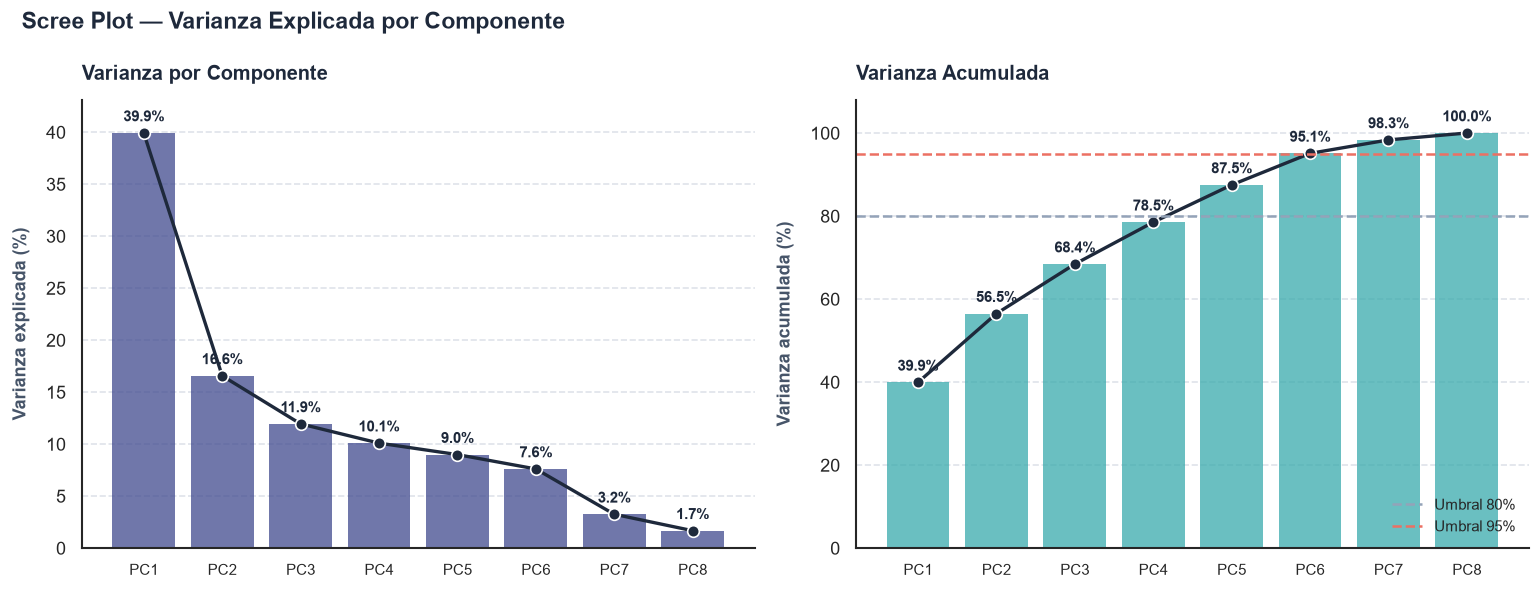

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 2 componente(s)



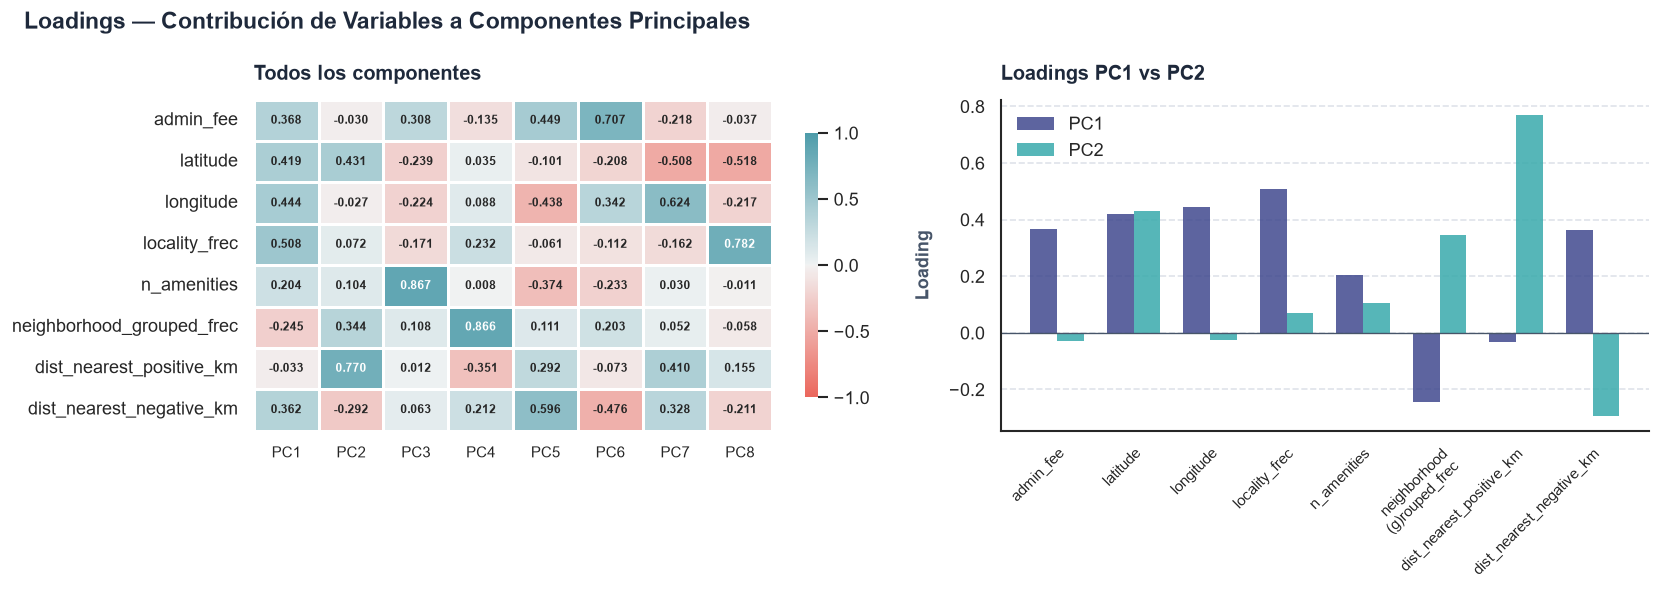


Error de reconstrucción promedio (MSE): 7.725252220550063e-31
Error de reconstrucción por variable:


dist_nearest_positive_km     1.327439e-31
admin_fee                    1.462233e-31
n_amenities                  3.677260e-31
neighborhood_grouped_frec    4.427954e-31
dist_nearest_negative_km     8.540054e-31
longitude                    1.157136e-30
locality_frec                1.289416e-30
latitude                     1.790156e-30
dtype: float64

In [96]:
df_features_test = auto_pca(df[numeric_pca_cols_lin].copy(), numeric_pca_cols_lin, interpret=True,metrics=True)

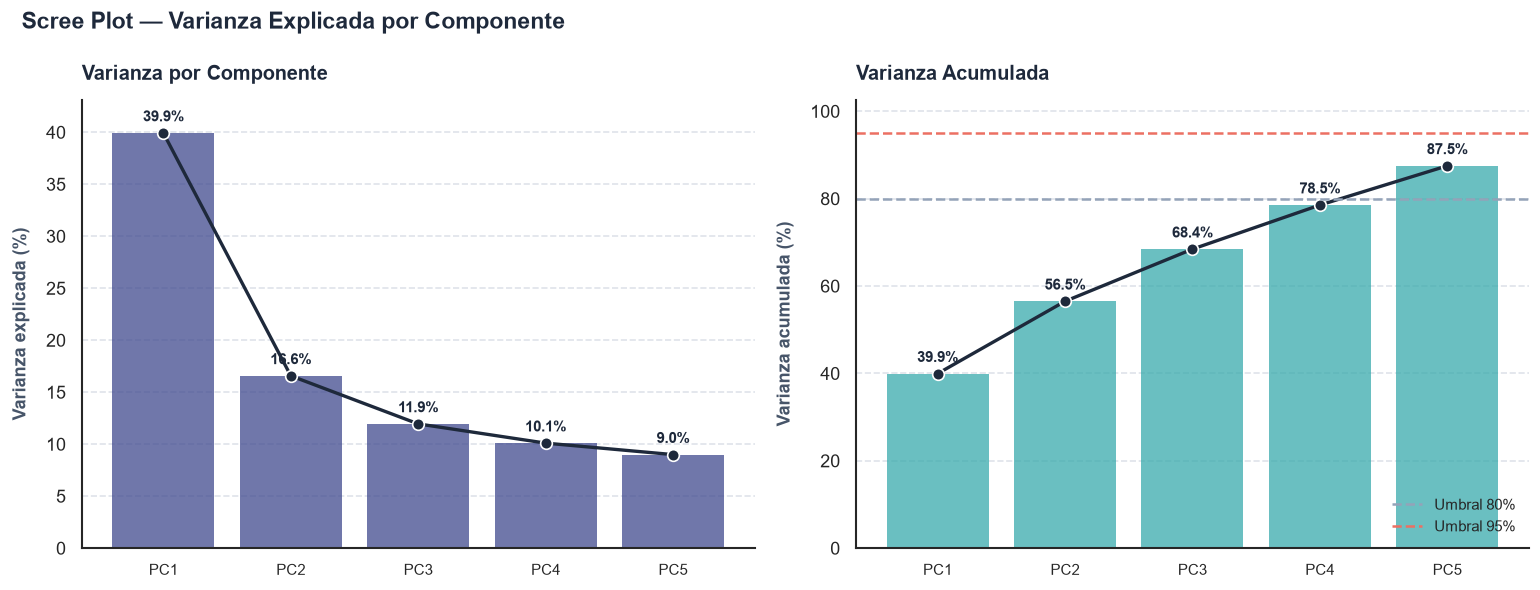

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 2 componente(s)



In [98]:
df_features_lin = auto_pca(df[numeric_pca_cols_lin].copy(), numeric_pca_cols_lin, 5)

In [99]:
df_features_lin

,pca0,pca1,pca2,pca3,pca4
0,1.070060,0.131355,0.377443,1.018761,0.386896
1,-1.758103,0.806469,-0.458661,-0.135289,-0.252589
2,1.478915,0.124474,-0.024658,1.311365,-1.002314
3,1.160097,0.317950,0.573799,1.080829,-1.308721
4,1.833820,-1.346223,0.365513,-0.541414,-0.255616
...,...,...,...,...,...
20437,-2.446446,0.242566,0.604072,0.084877,-0.749540
20438,-1.315829,0.198988,-0.051603,0.346994,0.629724
20439,-1.270513,-0.092510,1.750613,0.288424,-0.795390
20440,0.387429,0.733544,-1.630719,0.936650,0.646585


In [100]:
df_features_lin.shape[0] == df.shape[0]

True

In [105]:
X = sm.add_constant(df_features_lin)
y = df[target]

model_1 = sm.OLS(y, X).fit()

In [113]:
df_linreg_1 = pd.concat([X, y], axis=1)
df_linreg_1.drop(columns=['const'], inplace=True)

In [114]:
df_linreg_1

,pca0,pca1,pca2,pca3,pca4,price_amount
0,1.070060,0.131355,0.377443,1.018761,0.386896,8.800000e+08
1,-1.758103,0.806469,-0.458661,-0.135289,-0.252589,6.500000e+08
2,1.478915,0.124474,-0.024658,1.311365,-1.002314,6.250000e+08
3,1.160097,0.317950,0.573799,1.080829,-1.308721,4.700000e+08
4,1.833820,-1.346223,0.365513,-0.541414,-0.255616,1.170000e+09
...,...,...,...,...,...,...
20437,-2.446446,0.242566,0.604072,0.084877,-0.749540,5.799000e+08
20438,-1.315829,0.198988,-0.051603,0.346994,0.629724,6.000000e+08
20439,-1.270513,-0.092510,1.750613,0.288424,-0.795390,6.500000e+08
20440,0.387429,0.733544,-1.630719,0.936650,0.646585,1.870000e+08


In [116]:
X

,const,pca0,pca1,pca2,pca3,pca4
0,1.0,1.070060,0.131355,0.377443,1.018761,0.386896
1,1.0,-1.758103,0.806469,-0.458661,-0.135289,-0.252589
2,1.0,1.478915,0.124474,-0.024658,1.311365,-1.002314
3,1.0,1.160097,0.317950,0.573799,1.080829,-1.308721
4,1.0,1.833820,-1.346223,0.365513,-0.541414,-0.255616
...,...,...,...,...,...,...
20437,1.0,-2.446446,0.242566,0.604072,0.084877,-0.749540
20438,1.0,-1.315829,0.198988,-0.051603,0.346994,0.629724
20439,1.0,-1.270513,-0.092510,1.750613,0.288424,-0.795390
20440,1.0,0.387429,0.733544,-1.630719,0.936650,0.646585


In [118]:
vif_table(df_linreg_1, 'price_amount', [f'pca{i}' for i in range(5)])

,Variable,VIF,descartada,alto
0,pca0,1.0,None,False
1,pca3,1.0,None,False
2,pca1,1.0,None,False
3,pca2,1.0,None,False
4,pca4,1.0,None,False


Gracias a la ortogonalidad de las componentes el VIF de todos ellos es 1. Luego no hay redundancia en las caracteristicas

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,922592927.421143,3942695.299030,234.000565,0.000000,914864928.926668,930320925.915618
pca0,197809573.290430,2206347.464580,89.654769,0.000000,193484955.588230,202134190.992630
pca1,42151580.001128,3425389.049391,12.305633,0.000000,35437543.178857,48865616.823400
pca2,115988513.495089,4034724.046863,28.747570,0.000000,108080131.285728,123896895.704451
pca3,-120154106.843639,4388692.055104,-27.378113,0.000000,-128756294.692877,-111551918.994401
pca4,204883786.884212,4650483.346844,44.056450,0.000000,195768467.140422,213999106.628002


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,922592927.421143,3942695.299030,234.000565,0.000000,914864928.926668,930320925.915618
pca0,197809573.290430,2206347.464580,89.654769,0.000000,193484955.588230,202134190.992630
pca1,42151580.001128,3425389.049391,12.305633,0.000000,35437543.178857,48865616.823400
pca2,115988513.495089,4034724.046863,28.747570,0.000000,108080131.285728,123896895.704451
pca3,-120154106.843639,4388692.055104,-27.378113,0.000000,-128756294.692877,-111551918.994401
pca4,204883786.884212,4650483.346844,44.056450,0.000000,195768467.140422,213999106.628002


R**2: 0.36420351832799713
R**2 ajustado: 0.3640479603710407
F global: 2341.27
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 563,708,919.97


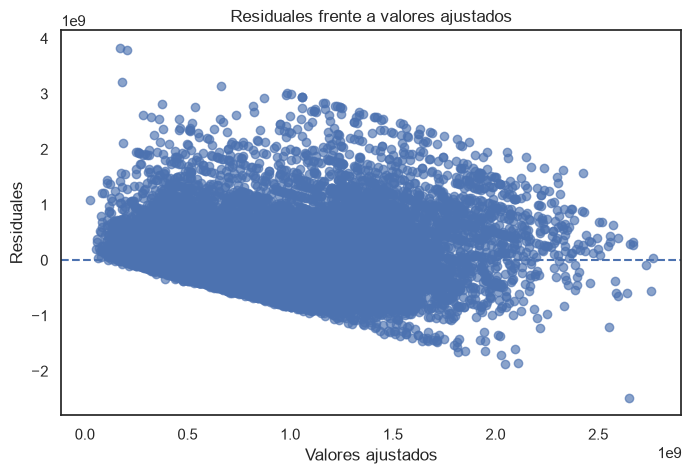

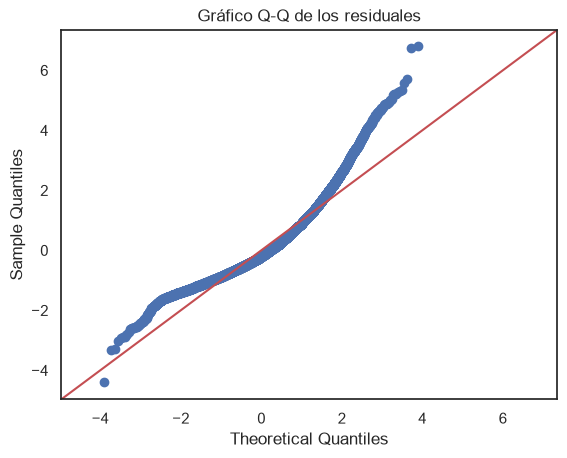

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,11798.60428,0.0,normalidad
1,Breusch-Pagan,606.69867,0.0,homocedasticidad
2,Ramsey RESET,51229.93539,0.0,forma funcional adecuada
3,Durbin-Watson,1.69581,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.6958. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 989
Observaciones con alto leverage (hat > 0.001): 1203
Observaciones influyentes (Cook D > 0.000): 1137


In [106]:
diagnosticador_modelo_1 = DiagnosticoOLS(model_1)
diagnosticador_modelo_1.reporte_completo()

### Usando `log_price_amount` (target)

In [119]:
X = sm.add_constant(df_features_lin)
y = np.log(df[target])

model_2 = sm.OLS(y, X).fit()

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.004187,4865.168463,0.000000,20.360965,20.377378
pca0,0.226501,0.002343,96.675102,0.000000,0.221909,0.231094
pca1,0.004780,0.003637,1.314208,0.188791,-0.002349,0.011910
pca2,0.098270,0.004284,22.936275,0.000000,0.089872,0.106667
pca3,-0.127869,0.004660,-27.437739,0.000000,-0.137004,-0.118734
pca4,0.154353,0.004938,31.256063,0.000000,0.144673,0.164032


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.004187,4865.168463,0.000000,20.360965,20.377378
pca0,0.226501,0.002343,96.675102,0.000000,0.221909,0.231094
pca2,0.098270,0.004284,22.936275,0.000000,0.089872,0.106667
pca3,-0.127869,0.004660,-27.437739,0.000000,-0.137004,-0.118734
pca4,0.154353,0.004938,31.256063,0.000000,0.144673,0.164032


R**2: 0.3621652428421379
R**2 ajustado: 0.36200918618791056
F global: 2320.73
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 0.60


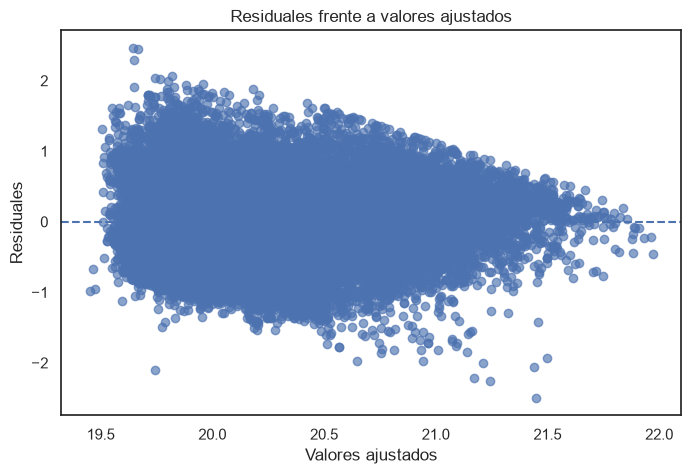

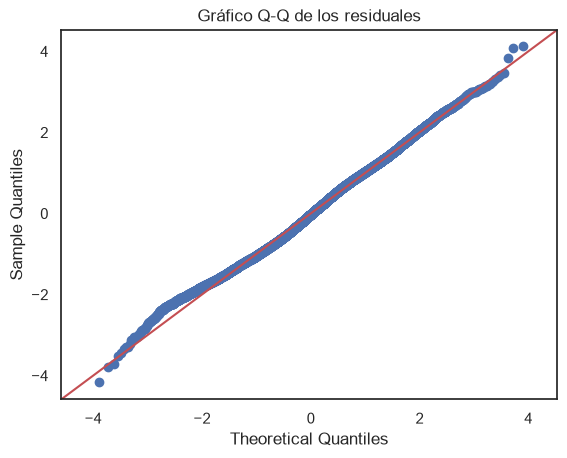

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,140.46760,0.0,normalidad
1,Breusch-Pagan,681.17386,0.0,homocedasticidad
2,Ramsey RESET,248.59557,0.0,forma funcional adecuada
3,Durbin-Watson,1.68300,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.6830. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 757
Observaciones con alto leverage (hat > 0.001): 1203
Observaciones influyentes (Cook D > 0.000): 730


In [120]:
diagnosticador_modelo_2 = DiagnosticoOLS(model_2)
diagnosticador_modelo_2.reporte_completo()

### Usando log log

In [124]:
log_feats = list(df_features_pca.columns)
log_feats.remove('price_amount_log')
print(log_feats)

['locality_frec', 'neighborhood_grouped_frec', 'admin_fee_log', 'latitude_log', 'longitude_log', 'n_amenities_log', 'dist_nearest_positive_km_log', 'dist_nearest_negative_km_log']


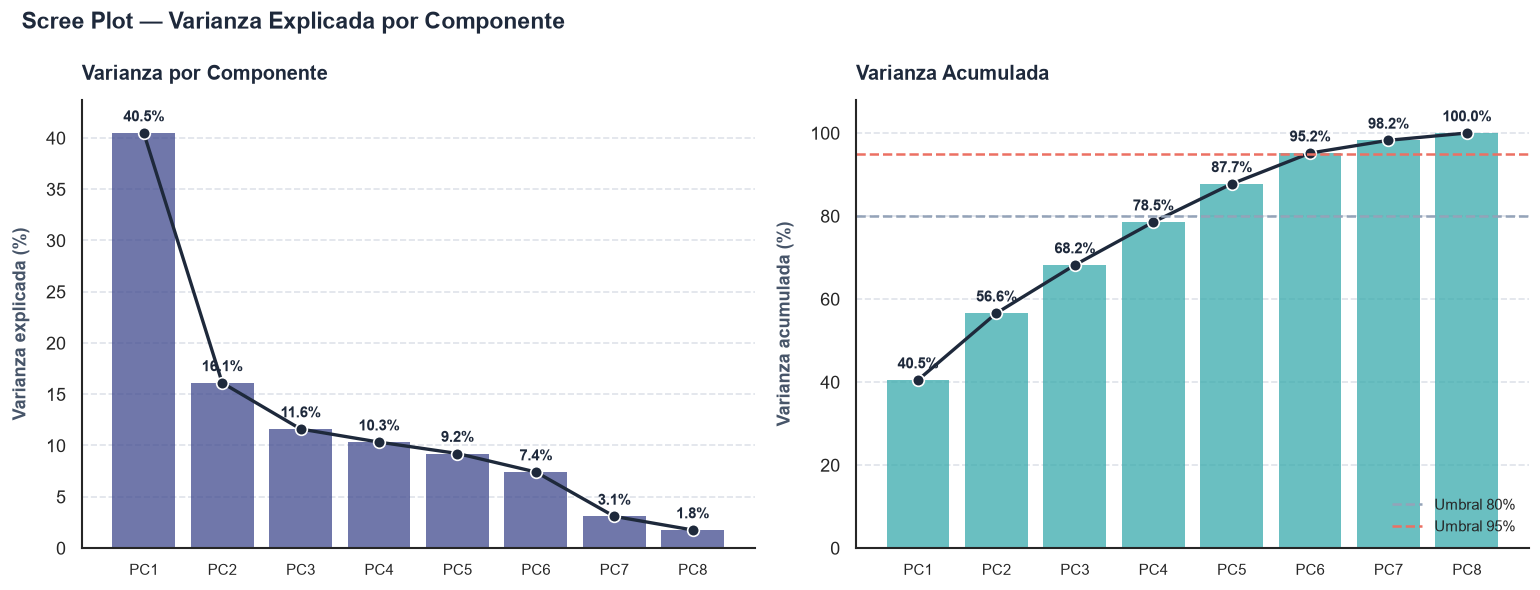

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 2 componente(s)



In [128]:
df_features_lin_log_test = auto_pca(df_features_pca.copy(), log_feats)

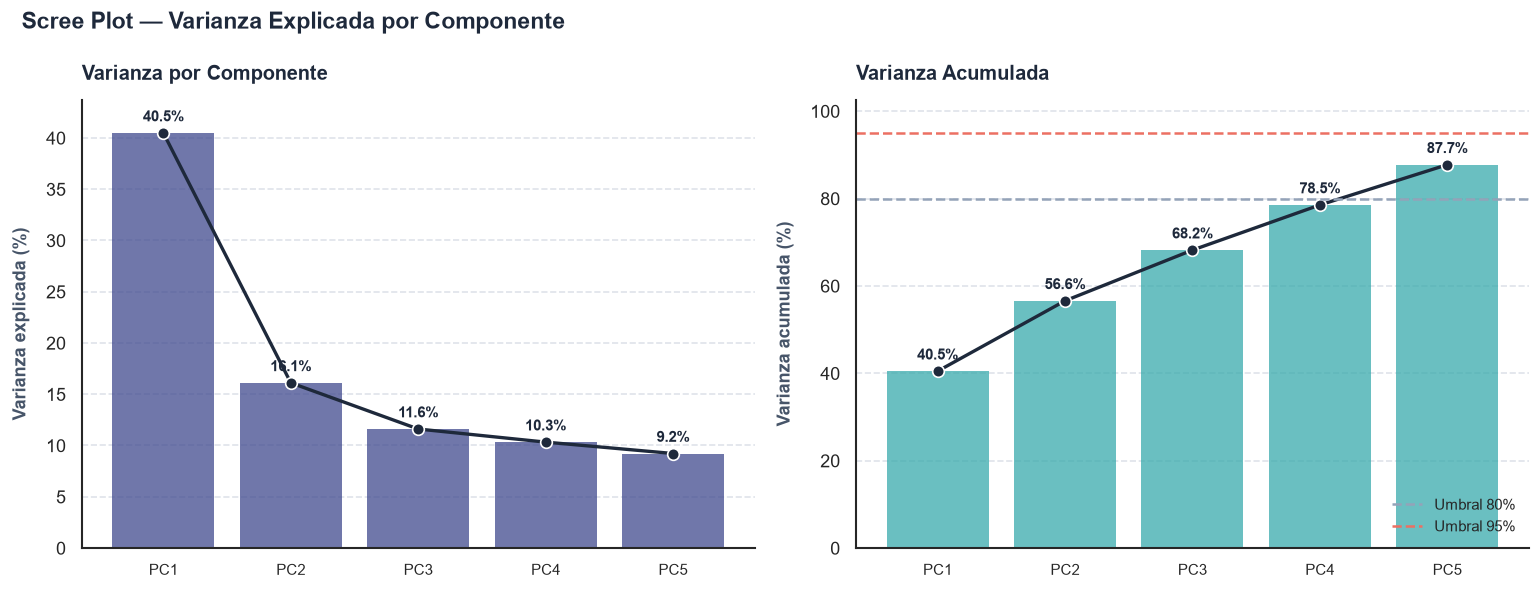

Criterios comunes para elegir el número de componentes:
  1. Umbral de varianza acumulada (80%, 90% o 95% según el contexto)
  2. Regla del codo: donde la curva del scree plot 'se aplana'
  3. Regla de Kaiser: conservar componentes con λ > 1 (solo aplica con datos estandarizados)

  Regla de Kaiser en este dataset: λ > 1 → 2 componente(s)



In [129]:
df_features_lin_log = auto_pca(df_features_pca.copy(), log_feats, n_comp=5)

In [130]:
df_features_lin_log

,pca0,pca1,pca2,pca3,pca4
0,1.186092,0.306680,0.560241,1.001890,0.294845
1,-1.653099,0.909998,-0.126569,-0.419411,-0.668852
2,1.743479,-0.103609,0.494004,1.154596,-0.878624
3,1.318786,0.267067,0.777351,0.755978,-0.938198
4,1.963663,-1.360041,0.508815,-0.514093,0.374936
...,...,...,...,...,...
20437,-2.677421,0.346171,1.007094,-0.273786,-0.726577
20438,-1.321864,0.376926,0.267387,0.606251,0.969772
20439,-1.185104,-0.179938,1.453953,0.040739,-0.417208
20440,0.064248,0.903012,-2.742748,1.287469,0.795080


In [131]:
X = sm.add_constant(df_features_lin_log)
y = df_features_pca["price_amount_log"]

In [132]:
df_lin_log_log = pd.concat([X,y], axis=1)

In [133]:
df_lin_log_log

,const,pca0,pca1,pca2,pca3,pca4,price_amount_log
0,1.0,1.186092,0.306680,0.560241,1.001890,0.294845,20.595432
1,1.0,-1.653099,0.909998,-0.126569,-0.419411,-0.668852,20.292483
2,1.0,1.743479,-0.103609,0.494004,1.154596,-0.878624,20.253262
3,1.0,1.318786,0.267067,0.777351,0.755978,-0.938198,19.968243
4,1.0,1.963663,-1.360041,0.508815,-0.514093,0.374936,20.880270
...,...,...,...,...,...,...,...
20437,1.0,-2.677421,0.346171,1.007094,-0.273786,-0.726577,20.178366
20438,1.0,-1.321864,0.376926,0.267387,0.606251,0.969772,20.212440
20439,1.0,-1.185104,-0.179938,1.453953,0.040739,-0.417208,20.292483
20440,1.0,0.064248,0.903012,-2.742748,1.287469,0.795080,19.046619


In [134]:
vif_table(df_lin_log_log, 'price_amount_log')

Aviso: 1 columna(s) de varianza cero, sin VIF definido: const


,Variable,VIF,descartada,alto
0,pca3,1.0,None,False
1,pca0,1.0,None,False
2,pca2,1.0,None,False
3,pca4,1.0,None,False
4,pca1,1.0,None,False
5,const,NaN,varianza cero,False


In [136]:
model_3 = sm.OLS(y, X).fit()

,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.004409,4619.483179,0.000000,20.360529,20.377815
pca0,0.218031,0.002450,88.980271,0.000000,0.213228,0.222834
pca1,-0.002492,0.003884,-0.641628,0.521122,-0.010105,0.005121
pca2,0.006586,0.004576,1.439149,0.150124,-0.002384,0.015555
pca3,-0.111397,0.004851,-22.964865,0.000000,-0.120905,-0.101889
pca4,-0.007381,0.005135,-1.437411,0.150616,-0.017445,0.002684


,coeficiente,error_estandar,t,p_valor,ci_lower,ci_upper
const,20.369172,0.004409,4619.483179,0.000000,20.360529,20.377815
pca0,0.218031,0.002450,88.980271,0.000000,0.213228,0.222834
pca3,-0.111397,0.004851,-22.964865,0.000000,-0.120905,-0.101889


R**2: 0.29251511049725976
R**2 ajustado: 0.2923420128045844
F global: 1689.88
p_valor prueba F: 0.0000e+00
Error Estándar Residual (RSE): 0.63


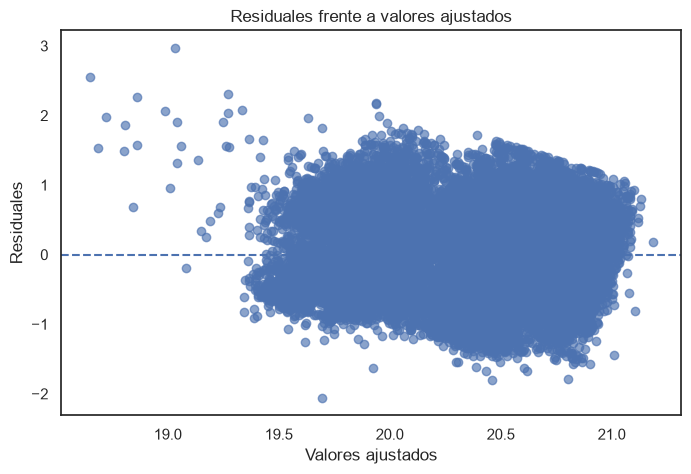

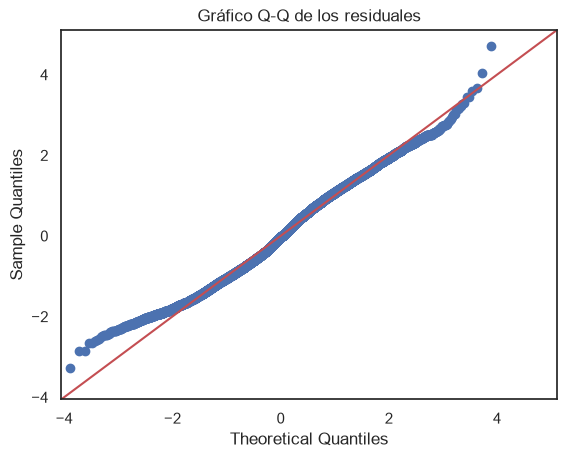

,prueba,estadistico,p_valor,H0
0,Jarque-Bera,377.06167,0.0,normalidad
1,Breusch-Pagan,715.72528,0.0,homocedasticidad
2,Ramsey RESET,335.63460,0.0,forma funcional adecuada
3,Durbin-Watson,1.66961,NaN,"sin autocorrelación de orden 1, lectura heurís..."


Jarque-Bera: se rechaza H0 al 5 %. los residuales no son normales.
Breusch-Pagan: se rechaza H0 al 5 %. hay evidencia de heterocedasticidad.
Ramsey RESET: se rechaza H0 al 5 %. hay evidencia de mala especificación de la forma funcional.
Durbin-Watson: estadístico = 1.6696. Sin p-valor, lectura heurística (≈2 sugiere ausencia de autocorrelación de orden 1).
Observaciones con residuos atípicos (|student| > 2): 551
Observaciones con alto leverage (hat > 0.001): 1098
Observaciones influyentes (Cook D > 0.000): 895


In [137]:
diagnosticador_modelo_3 = DiagnosticoOLS(model_3)
diagnosticador_modelo_3.reporte_completo()

Note que en general los modelos pre procesados con PCA fueron peores que los ajustados con las variables sin transformar en `notebook/model_OLS.ipynb`, esto ocurre ya que PCA solo extrae las compoinetnes que mejor explican la variabilidad del propio conjunto de predictores $X$, y esos componentes no son necesariamente aquellos (direcciones) que mejor describen o predicen $y$.